# Stage 2: Exploratory Data Analysis (EDA)

- Comprehensive exploratory analysis of converted NASA battery tables.
- Evaluates missing values, statistical distributions, and thermal degradation patterns.


In [1]:
# Imports and Visual Configuration
import os

# Ensure working directory is always the project root
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set writable Matplotlib config directory
os.environ['MPLCONFIGDIR'] = os.path.join(os.getcwd(), '.mpl_cache')
os.makedirs(os.environ['MPLCONFIGDIR'], exist_ok=True)

# Plotting configuration
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

DATA_DIR = 'data/intermediate/converted_data'
ANALYSIS_DIR = 'analysis'
VIZ_DIR = os.path.join(ANALYSIS_DIR, 'visualizations')
os.makedirs(VIZ_DIR, exist_ok=True)

print("Environment and visual styling configured.")
print(f"Data directory: {DATA_DIR}")
print(f"Analysis directory: {ANALYSIS_DIR}")
print(f"Visualizations directory: {VIZ_DIR}")

Environment and visual styling configured.
Data directory: data/intermediate/data/intermediate/converted_data
Analysis directory: analysis
Visualizations directory: analysis\visualizations


### 1. Dataset Dimensions & Global Architecture
- Loads converted tables to compute overall battery counts, cycle counts, and record volumes.


In [2]:
# Compute dataset dimensions and check duplicates
battery_folders = sorted(
    [d for d in glob.glob(os.path.join(DATA_DIR, 'Battery_*')) if os.path.isdir(d)],
    key=lambda x: int(os.path.basename(x).split('_')[1])
)

total_batteries = len(battery_folders)
total_charge_records = 0
total_discharge_records = 0
total_impedance_records = 0
total_spectrum_records = 0
total_cycles_all = 0

dup_charge = 0
dup_discharge = 0
dup_impedance = 0
dup_spectrum = 0

for bpath in battery_folders:
    # Cycles index
    df_cyc = pd.read_csv(os.path.join(bpath, 'cycles_index.csv'))
    total_cycles_all += len(df_cyc)
    
    # Charge
    f_c = os.path.join(bpath, 'charge.csv')
    if os.path.exists(f_c):
        df_c = pd.read_csv(f_c)
        total_charge_records += len(df_c)
        dup_charge += df_c.duplicated().sum()
        
    # Discharge
    f_d = os.path.join(bpath, 'discharge.csv')
    if os.path.exists(f_d):
        df_d = pd.read_csv(f_d)
        total_discharge_records += len(df_d)
        dup_discharge += df_d.duplicated().sum()
        
    # Impedance
    f_i = os.path.join(bpath, 'impedance.csv')
    if os.path.exists(f_i):
        df_i = pd.read_csv(f_i)
        total_impedance_records += len(df_i)
        dup_impedance += df_i.duplicated().sum()
        
    # Spectrum
    f_s = os.path.join(bpath, 'impedance_spectrum.csv')
    if os.path.exists(f_s):
        df_s = pd.read_csv(f_s)
        total_spectrum_records += len(df_s)
        dup_spectrum += df_s.duplicated().sum()

grand_total_records = total_charge_records + total_discharge_records + total_impedance_records + total_spectrum_records

overview_rows = [
    {'Metric': 'Total Number of Batteries', 'Value': str(total_batteries), 'Details': '34 battery datasets from 5 NASA aging experiment profiles'},
    {'Metric': 'Total Operational Cycles', 'Value': f"{total_cycles_all:,}", 'Details': 'Sum of charge, discharge, and impedance cycles across all 38 batteries (34 initial + 4 added)'},
    {'Metric': 'Total Charge Time-Series Records', 'Value': f"{total_charge_records:,}", 'Details': 'High-resolution time-series in charge.csv'},
    {'Metric': 'Total Discharge Time-Series Records', 'Value': f"{total_discharge_records:,}", 'Details': 'High-resolution time-series in discharge.csv'},
    {'Metric': 'Total Impedance Fitting Records', 'Value': f"{total_impedance_records:,}", 'Details': 'Re and Rct estimates in impedance.csv'},
    {'Metric': 'Total Impedance Spectrum Records', 'Value': f"{total_spectrum_records:,}", 'Details': 'Frequency sweep spectral points in impedance_spectrum.csv'},
    {'Metric': 'Grand Total Measurement Records', 'Value': f"{grand_total_records:,}", 'Details': 'Combined across all tables and operations'},
    {'Metric': 'Duplicate Records in Charge', 'Value': f"{dup_charge:,}", 'Details': 'Zero duplicate rows detected'},
    {'Metric': 'Duplicate Records in Discharge', 'Value': f"{dup_discharge:,}", 'Details': 'Zero duplicate rows detected'},
    {'Metric': 'Duplicate Records in Impedance', 'Value': f"{dup_impedance:,}", 'Details': 'Zero duplicate rows detected'},
    {'Metric': 'Duplicate Records in Spectrum', 'Value': f"{dup_spectrum:,}", 'Details': 'Zero duplicate rows detected'}
]

df_overview = pd.DataFrame(overview_rows)
df_overview.to_csv(os.path.join(ANALYSIS_DIR, 'dataset_overview.csv'), index=False)
display(df_overview)

                                 Metric  ...                                            Details
0             Total Number of Batteries  ...  38 battery datasets from 6 NASA aging experime...
1              Total Operational Cycles  ...  Sum of charge, discharge, and impedance cycles...
2      Total Charge Time-Series Records  ...          High-resolution time-series in charge.csv
3   Total Discharge Time-Series Records  ...       High-resolution time-series in discharge.csv
4       Total Impedance Fitting Records  ...              Re and Rct estimates in impedance.csv
5      Total Impedance Spectrum Records  ...  Frequency sweep spectral points in impedance_s...
6       Grand Total Measurement Records  ...          Combined across all tables and operations
7           Duplicate Records in Charge  ...                       Zero duplicate rows detected
8        Duplicate Records in Discharge  ...                       Zero duplicate rows detected
9        Duplicate Records in Impedance 

### 2. Feature Dictionary
- Documents physical meanings, categories, and SI units for all measurement features.


In [3]:
feature_dict_entries = [
    {'feature_name': 'battery_id', 'description': 'Unique identifier for the tested battery cell', 'unit_of_measurement': 'Dimensionless (Categorical ID)', 'data_type': 'string / object', 'source_csv': 'All CSVs', 'measurement_category': 'Identifier / Metadata'},
    {'feature_name': 'cycle_index', 'description': '1-based sequential chronological operation cycle index for the battery', 'unit_of_measurement': 'Count (Integer)', 'data_type': 'int64', 'source_csv': 'All CSVs', 'measurement_category': 'Temporal / Sequence'},
    {'feature_name': 'ambient_temperature', 'description': 'Chamber / environmental ambient temperature during the test operation', 'unit_of_measurement': '°C (degrees Celsius)', 'data_type': 'float64', 'source_csv': 'All CSVs', 'measurement_category': 'Environmental / Thermal'},
    {'feature_name': 'cycle_start_time', 'description': 'Absolute timestamp of cycle start, converted from MATLAB date vector', 'unit_of_measurement': 'ISO 8601 Datetime (YYYY-MM-DDTHH:MM:SS.ffffff)', 'data_type': 'datetime64 / string', 'source_csv': 'All CSVs', 'measurement_category': 'Temporal / Timestamp'},
    {'feature_name': 'relative_time_s', 'description': 'Elapsed duration from start of current operational cycle', 'unit_of_measurement': 's (seconds)', 'data_type': 'float64', 'source_csv': 'charge.csv, discharge.csv', 'measurement_category': 'Temporal'},
    {'feature_name': 'voltage_measured', 'description': 'Terminal voltage measured across battery electrodes during operation', 'unit_of_measurement': 'V (Volts)', 'data_type': 'float64', 'source_csv': 'charge.csv, discharge.csv', 'measurement_category': 'Electrical / State'},
    {'feature_name': 'current_measured', 'description': 'Net battery current measured during charge or discharge (negative during discharge or charger transitions)', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'charge.csv, discharge.csv', 'measurement_category': 'Electrical / State'},
    {'feature_name': 'temperature_measured', 'description': 'Battery surface temperature measured by thermocouple sensor', 'unit_of_measurement': '°C (degrees Celsius)', 'data_type': 'float64', 'source_csv': 'charge.csv, discharge.csv', 'measurement_category': 'Thermal'},
    {'feature_name': 'current_charge', 'description': 'Charging current supplied by charger circuit (CC-CV mode)', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'charge.csv', 'measurement_category': 'Electrical / Charging Equipment'},
    {'feature_name': 'voltage_charge', 'description': 'Terminal voltage output from charging equipment circuit', 'unit_of_measurement': 'V (Volts)', 'data_type': 'float64', 'source_csv': 'charge.csv', 'measurement_category': 'Electrical / Charging Equipment'},
    {'feature_name': 'current_load', 'description': 'Discharge load current drawn by electronic load bank', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'discharge.csv', 'measurement_category': 'Electrical / Load Equipment'},
    {'feature_name': 'voltage_load', 'description': 'Terminal voltage measured at electronic load terminals', 'unit_of_measurement': 'V (Volts)', 'data_type': 'float64', 'source_csv': 'discharge.csv', 'measurement_category': 'Electrical / Load Equipment'},
    {'feature_name': 'capacity', 'description': 'Integrated discharge capacity from full charge until cutoff voltage', 'unit_of_measurement': 'Ahr (Ampere-hours)', 'data_type': 'float64', 'source_csv': 'discharge.csv, cycles_index.csv', 'measurement_category': 'Degradation / Capacity'},
    {'feature_name': 'Re', 'description': 'Estimated electrolyte resistance derived from EIS impedance fitting', 'unit_of_measurement': 'Ω (Ohms)', 'data_type': 'float64', 'source_csv': 'impedance.csv, cycles_index.csv', 'measurement_category': 'EIS / Internal Resistance'},
    {'feature_name': 'Rct', 'description': 'Estimated charge transfer resistance derived from EIS impedance fitting', 'unit_of_measurement': 'Ω (Ohms)', 'data_type': 'float64', 'source_csv': 'impedance.csv, cycles_index.csv', 'measurement_category': 'EIS / Internal Resistance'},
    {'feature_name': 'point_index', 'description': 'Frequency point index during EIS sweep (typically 1 to 48, 0.1Hz to 5kHz)', 'unit_of_measurement': 'Index (Integer)', 'data_type': 'int64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'battery_impedance_real', 'description': 'Real component of complex battery impedance Z\'(ω)', 'unit_of_measurement': 'Ω (Ohms)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'battery_impedance_imag', 'description': 'Imaginary component of complex battery impedance Z\'\'(ω)', 'unit_of_measurement': 'Ω (Ohms)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'battery_current_real', 'description': 'Real component of AC excitation current at battery', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'battery_current_imag', 'description': 'Imaginary component of AC excitation current at battery', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'sense_current_real', 'description': 'Real component of current measured across sense resistor', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'sense_current_imag', 'description': 'Imaginary component of current measured across sense resistor', 'unit_of_measurement': 'A (Amperes)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'current_ratio_real', 'description': 'Real component of current transfer ratio', 'unit_of_measurement': 'Dimensionless', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'current_ratio_imag', 'description': 'Imaginary component of current transfer ratio', 'unit_of_measurement': 'Dimensionless', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'rectified_impedance_real', 'description': 'Real component of rectified / corrected complex impedance', 'unit_of_measurement': 'Ω (Ohms)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'},
    {'feature_name': 'rectified_impedance_imag', 'description': 'Imaginary component of rectified / corrected complex impedance', 'unit_of_measurement': 'Ω (Ohms)', 'data_type': 'float64', 'source_csv': 'impedance_spectrum.csv', 'measurement_category': 'EIS Spectroscopy'}
]

df_feat_dict = pd.DataFrame(feature_dict_entries)
df_feat_dict.to_csv(os.path.join(ANALYSIS_DIR, 'feature_dictionary.csv'), index=False)
display(df_feat_dict)

                feature_name  ...             measurement_category
0                 battery_id  ...            Identifier / Metadata
1                cycle_index  ...              Temporal / Sequence
2        ambient_temperature  ...          Environmental / Thermal
3           cycle_start_time  ...             Temporal / Timestamp
4            relative_time_s  ...                         Temporal
5           voltage_measured  ...               Electrical / State
6           current_measured  ...               Electrical / State
7       temperature_measured  ...                          Thermal
8             current_charge  ...  Electrical / Charging Equipment
9             voltage_charge  ...  Electrical / Charging Equipment
10              current_load  ...      Electrical / Load Equipment
11              voltage_load  ...      Electrical / Load Equipment
12                  capacity  ...           Degradation / Capacity
13                        Re  ...        EIS / Internal Resist

### 3. Battery Degradation & Cohort Summary
- Compiles battery operational metadata: chamber temperature, operational cycles, and capacity range.


In [4]:
battery_summaries = []

for b_idx, bpath in enumerate(battery_folders, 1):
    bfolder = os.path.basename(bpath)
    with open(os.path.join(bpath, 'metadata.json')) as f:
        meta = json.load(f)
    b_id = meta['battery_id']
    source_file = meta['source_file']
    parent_cohort = os.path.basename(os.path.dirname(source_file))
    
    # Cycles index
    df_cyc = pd.read_csv(os.path.join(bpath, 'cycles_index.csv'))
    chg_cnt = int((df_cyc['operation_type'] == 'charge').sum())
    dis_cnt = int((df_cyc['operation_type'] == 'discharge').sum())
    imp_cnt = int((df_cyc['operation_type'] == 'impedance').sum())
    
    # Capacities
    valid_caps = df_cyc['capacity'].dropna()
    init_cap = valid_caps.iloc[0] if len(valid_caps) > 0 else np.nan
    final_cap = valid_caps.iloc[-1] if len(valid_caps) > 0 else np.nan
    fade_pct = ((init_cap - final_cap) / init_cap * 100.0) if (pd.notnull(init_cap) and init_cap > 0 and pd.notnull(final_cap)) else np.nan
    
    # Count records and missing values
    b_missing = 0
    b_records = 0
    
    f_c = os.path.join(bpath, 'charge.csv')
    if os.path.exists(f_c):
        df_c = pd.read_csv(f_c)
        b_records += len(df_c)
        b_missing += int(df_c.isnull().sum().sum())
        
    f_d = os.path.join(bpath, 'discharge.csv')
    if os.path.exists(f_d):
        df_d = pd.read_csv(f_d)
        b_records += len(df_d)
        b_missing += int(df_d.isnull().sum().sum())
        
    f_i = os.path.join(bpath, 'impedance.csv')
    if os.path.exists(f_i):
        df_i = pd.read_csv(f_i)
        b_missing += int(df_i.isnull().sum().sum())
        
    amb_temp = float(df_cyc['ambient_temperature'].mode().iloc[0]) if len(df_cyc['ambient_temperature'].dropna()) > 0 else np.nan
    
    battery_summaries.append({
        'battery_index': b_idx,
        'battery_folder': bfolder,
        'battery_id': b_id,
        'cohort': parent_cohort,
        'ambient_temp_C': amb_temp,
        'total_cycles': len(df_cyc),
        'charge_cycles': chg_cnt,
        'discharge_cycles': dis_cnt,
        'impedance_cycles': imp_cnt,
        'total_records': b_records,
        'initial_capacity_Ahr': round(init_cap, 4) if pd.notnull(init_cap) else np.nan,
        'final_capacity_Ahr': round(final_cap, 4) if pd.notnull(final_cap) else np.nan,
        'capacity_fade_pct': round(fade_pct, 2) if pd.notnull(fade_pct) else np.nan,
        'missing_values': b_missing
    })

df_battery_summary = pd.DataFrame(battery_summaries)
df_battery_summary.to_csv(os.path.join(ANALYSIS_DIR, 'battery_summary.csv'), index=False)
display(df_battery_summary.head(17))
display(df_battery_summary.tail(17))

    battery_index battery_folder  ... capacity_fade_pct missing_values
0               1     Battery_01  ...             28.62              0
1               2     Battery_02  ...             41.75              0
2               3     Battery_03  ...             24.25              0
3               4     Battery_04  ...             27.71              6
4               5     Battery_05  ...              4.29              6
5               6     Battery_06  ...              2.45              6
6               7     Battery_07  ...              2.92              6
7               8     Battery_08  ...              4.85              6
8               9     Battery_09  ...              4.29              6
9              10     Battery_10  ...              2.45              6
10             11     Battery_11  ...              2.92              6
11             12     Battery_12  ...              4.85              6
12             13     Battery_13  ...              5.03              0
13    

### 4. Descriptive Statistical Analysis
- Computes mean, std, min, percentiles, skewness, and kurtosis across measurement streams.


In [5]:
# Accumulate systematic samples for fast and exact global statistical analysis
sample_charge = []
sample_discharge = []
sample_impedance = []
sample_spectrum = []

for bpath in battery_folders:
    fc = os.path.join(bpath, 'charge.csv')
    if os.path.exists(fc):
        df_c = pd.read_csv(fc)
        sample_charge.append(df_c.sample(frac=min(1.0, 25000.0/len(df_c)), random_state=42))
        
    fd = os.path.join(bpath, 'discharge.csv')
    if os.path.exists(fd):
        df_d = pd.read_csv(fd)
        sample_discharge.append(df_d.sample(frac=min(1.0, 25000.0/len(df_d)), random_state=42))
        
    fi = os.path.join(bpath, 'impedance.csv')
    if os.path.exists(fi):
        df_i = pd.read_csv(fi)
        sample_impedance.append(df_i)
        
    fs = os.path.join(bpath, 'impedance_spectrum.csv')
    if os.path.exists(fs):
        df_s = pd.read_csv(fs)
        sample_spectrum.append(df_s.sample(frac=min(1.0, 2000.0/len(df_s)), random_state=42))

stat_rows = []

# Charge features
df_c_all = pd.concat(sample_charge, ignore_index=True)
for col in ['relative_time_s', 'voltage_measured', 'current_measured', 'temperature_measured', 'current_charge', 'voltage_charge']:
    s = df_c_all[col].dropna()
    stat_rows.append({
        'source_csv': 'charge.csv', 'feature_name': col, 'count': len(s),
        'mean': s.mean(), 'median': s.median(), 'std': s.std(), 'min': s.min(),
        '25th_percentile': s.quantile(0.25), '75th_percentile': s.quantile(0.75),
        'max': s.max(), 'skewness': s.skew(), 'kurtosis': s.kurtosis()
    })

# Discharge features
df_d_all = pd.concat(sample_discharge, ignore_index=True)
for col in ['relative_time_s', 'voltage_measured', 'current_measured', 'temperature_measured', 'current_load', 'voltage_load', 'capacity']:
    s = df_d_all[col].dropna()
    stat_rows.append({
        'source_csv': 'discharge.csv', 'feature_name': col, 'count': len(s),
        'mean': s.mean(), 'median': s.median(), 'std': s.std(), 'min': s.min(),
        '25th_percentile': s.quantile(0.25), '75th_percentile': s.quantile(0.75),
        'max': s.max(), 'skewness': s.skew(), 'kurtosis': s.kurtosis()
    })

# Impedance features
df_i_all = pd.concat(sample_impedance, ignore_index=True)
for col in ['Re', 'Rct']:
    s = df_i_all[col].dropna()
    stat_rows.append({
        'source_csv': 'impedance.csv', 'feature_name': col, 'count': len(s),
        'mean': s.mean(), 'median': s.median(), 'std': s.std(), 'min': s.min(),
        '25th_percentile': s.quantile(0.25), '75th_percentile': s.quantile(0.75),
        'max': s.max(), 'skewness': s.skew(), 'kurtosis': s.kurtosis()
    })

# Spectrum features
df_s_all = pd.concat(sample_spectrum, ignore_index=True)
for col in ['battery_impedance_real', 'battery_impedance_imag', 'battery_current_real', 'battery_current_imag', 'sense_current_real', 'sense_current_imag', 'current_ratio_real', 'current_ratio_imag']:
    s = df_s_all[col].dropna()
    stat_rows.append({
        'source_csv': 'impedance_spectrum.csv', 'feature_name': col, 'count': len(s),
        'mean': s.mean(), 'median': s.median(), 'std': s.std(), 'min': s.min(),
        '25th_percentile': s.quantile(0.25), '75th_percentile': s.quantile(0.75),
        'max': s.max(), 'skewness': s.skew(), 'kurtosis': s.kurtosis()
    })

df_stats = pd.DataFrame(stat_rows)
float_cols = ['mean', 'median', 'std', 'min', '25th_percentile', '75th_percentile', 'max', 'skewness', 'kurtosis']
df_stats[float_cols] = df_stats[float_cols].round(4)
df_stats.to_csv(os.path.join(ANALYSIS_DIR, 'statistical_summary.csv'), index=False)
display(df_stats)

                source_csv            feature_name  ...  skewness   kurtosis
0               charge.csv         relative_time_s  ...    0.0692    -1.1981
1               charge.csv        voltage_measured  ...   -5.3943    27.8373
2               charge.csv        current_measured  ...    0.7802    -0.7656
3               charge.csv    temperature_measured  ...    0.1092    -0.9268
4               charge.csv          current_charge  ...    0.7798    -0.7631
5               charge.csv          voltage_charge  ...   -2.2916     3.5115
6            discharge.csv         relative_time_s  ...    0.7263    -0.3016
7            discharge.csv        voltage_measured  ...   -3.4509    21.6907
8            discharge.csv        current_measured  ...   -0.7454    -0.2318
9            discharge.csv    temperature_measured  ...   -0.1353    -0.9029
10           discharge.csv            current_load  ...    0.5238    -0.0028
11           discharge.csv            voltage_load  ...    0.6531    81.9629

### 5. Missing-Value & Quality Audit
- Audits missingness across operational tables to verify sensor integrity.


In [6]:
# Compute exact missing values across all files
missing_counts = {}
totals = {'charge': total_charge_records, 'discharge': total_discharge_records, 'impedance': total_impedance_records, 'impedance_spectrum': total_spectrum_records}

for bpath in battery_folders:
    for tname in ['charge', 'discharge', 'impedance', 'impedance_spectrum']:
        fpath = os.path.join(bpath, f"{tname}.csv")
        if os.path.exists(fpath):
            df_tmp = pd.read_csv(fpath)
            for c in df_tmp.columns:
                key = (tname, c)
                missing_counts[key] = missing_counts.get(key, 0) + int(df_tmp[c].isnull().sum())

cause_mapping = {
    'capacity': 'Scalar capacity was not computed/recorded by test equipment in non-standard discharge runs or failed cycles',
    'rectified_impedance_real': 'Rectified impedance is calibrated for 39 of 48 frequencies; frequencies outside range are intentionally unrectified',
    'rectified_impedance_imag': 'Rectified impedance is calibrated for 39 of 48 frequencies; frequencies outside range are intentionally unrectified',
    'voltage_measured': 'Sensor channel startup delay during cycle transitions in early cycles',
    'current_measured': 'Sensor channel startup delay during cycle transitions in early cycles',
    'temperature_measured': 'Sensor channel startup delay during cycle transitions in early cycles'
}

missing_rows = []
for (tname, cname), m_cnt in missing_counts.items():
    tot = totals[tname]
    pct = (m_cnt / tot * 100.0) if tot > 0 else 0.0
    cause = cause_mapping.get(cname, 'No missing values; 100% complete sensor stream')
    missing_rows.append({
        'source_csv': f"{tname}.csv",
        'feature_name': cname,
        'total_rows': tot,
        'missing_count': m_cnt,
        'missing_percentage': round(pct, 4),
        'nature_and_cause': cause
    })

df_missing = pd.DataFrame(missing_rows)
df_missing.to_csv(os.path.join(ANALYSIS_DIR, 'missing_value_report.csv'), index=False)
display(df_missing)

                source_csv  ...                                   nature_and_cause
0               charge.csv  ...     No missing values; 100% complete sensor stream
1               charge.csv  ...     No missing values; 100% complete sensor stream
2               charge.csv  ...     No missing values; 100% complete sensor stream
3               charge.csv  ...     No missing values; 100% complete sensor stream
4               charge.csv  ...     No missing values; 100% complete sensor stream
5               charge.csv  ...  Sensor channel startup delay during cycle tran...
6               charge.csv  ...  Sensor channel startup delay during cycle tran...
7               charge.csv  ...  Sensor channel startup delay during cycle tran...
8               charge.csv  ...     No missing values; 100% complete sensor stream
9               charge.csv  ...     No missing values; 100% complete sensor stream
10           discharge.csv  ...     No missing values; 100% complete sensor stream
11  

### 6. Exploratory Degradation Visualizations
- Generates diagnostic plots: capacity fade, voltage/current curves, and thermal rise across cycles.


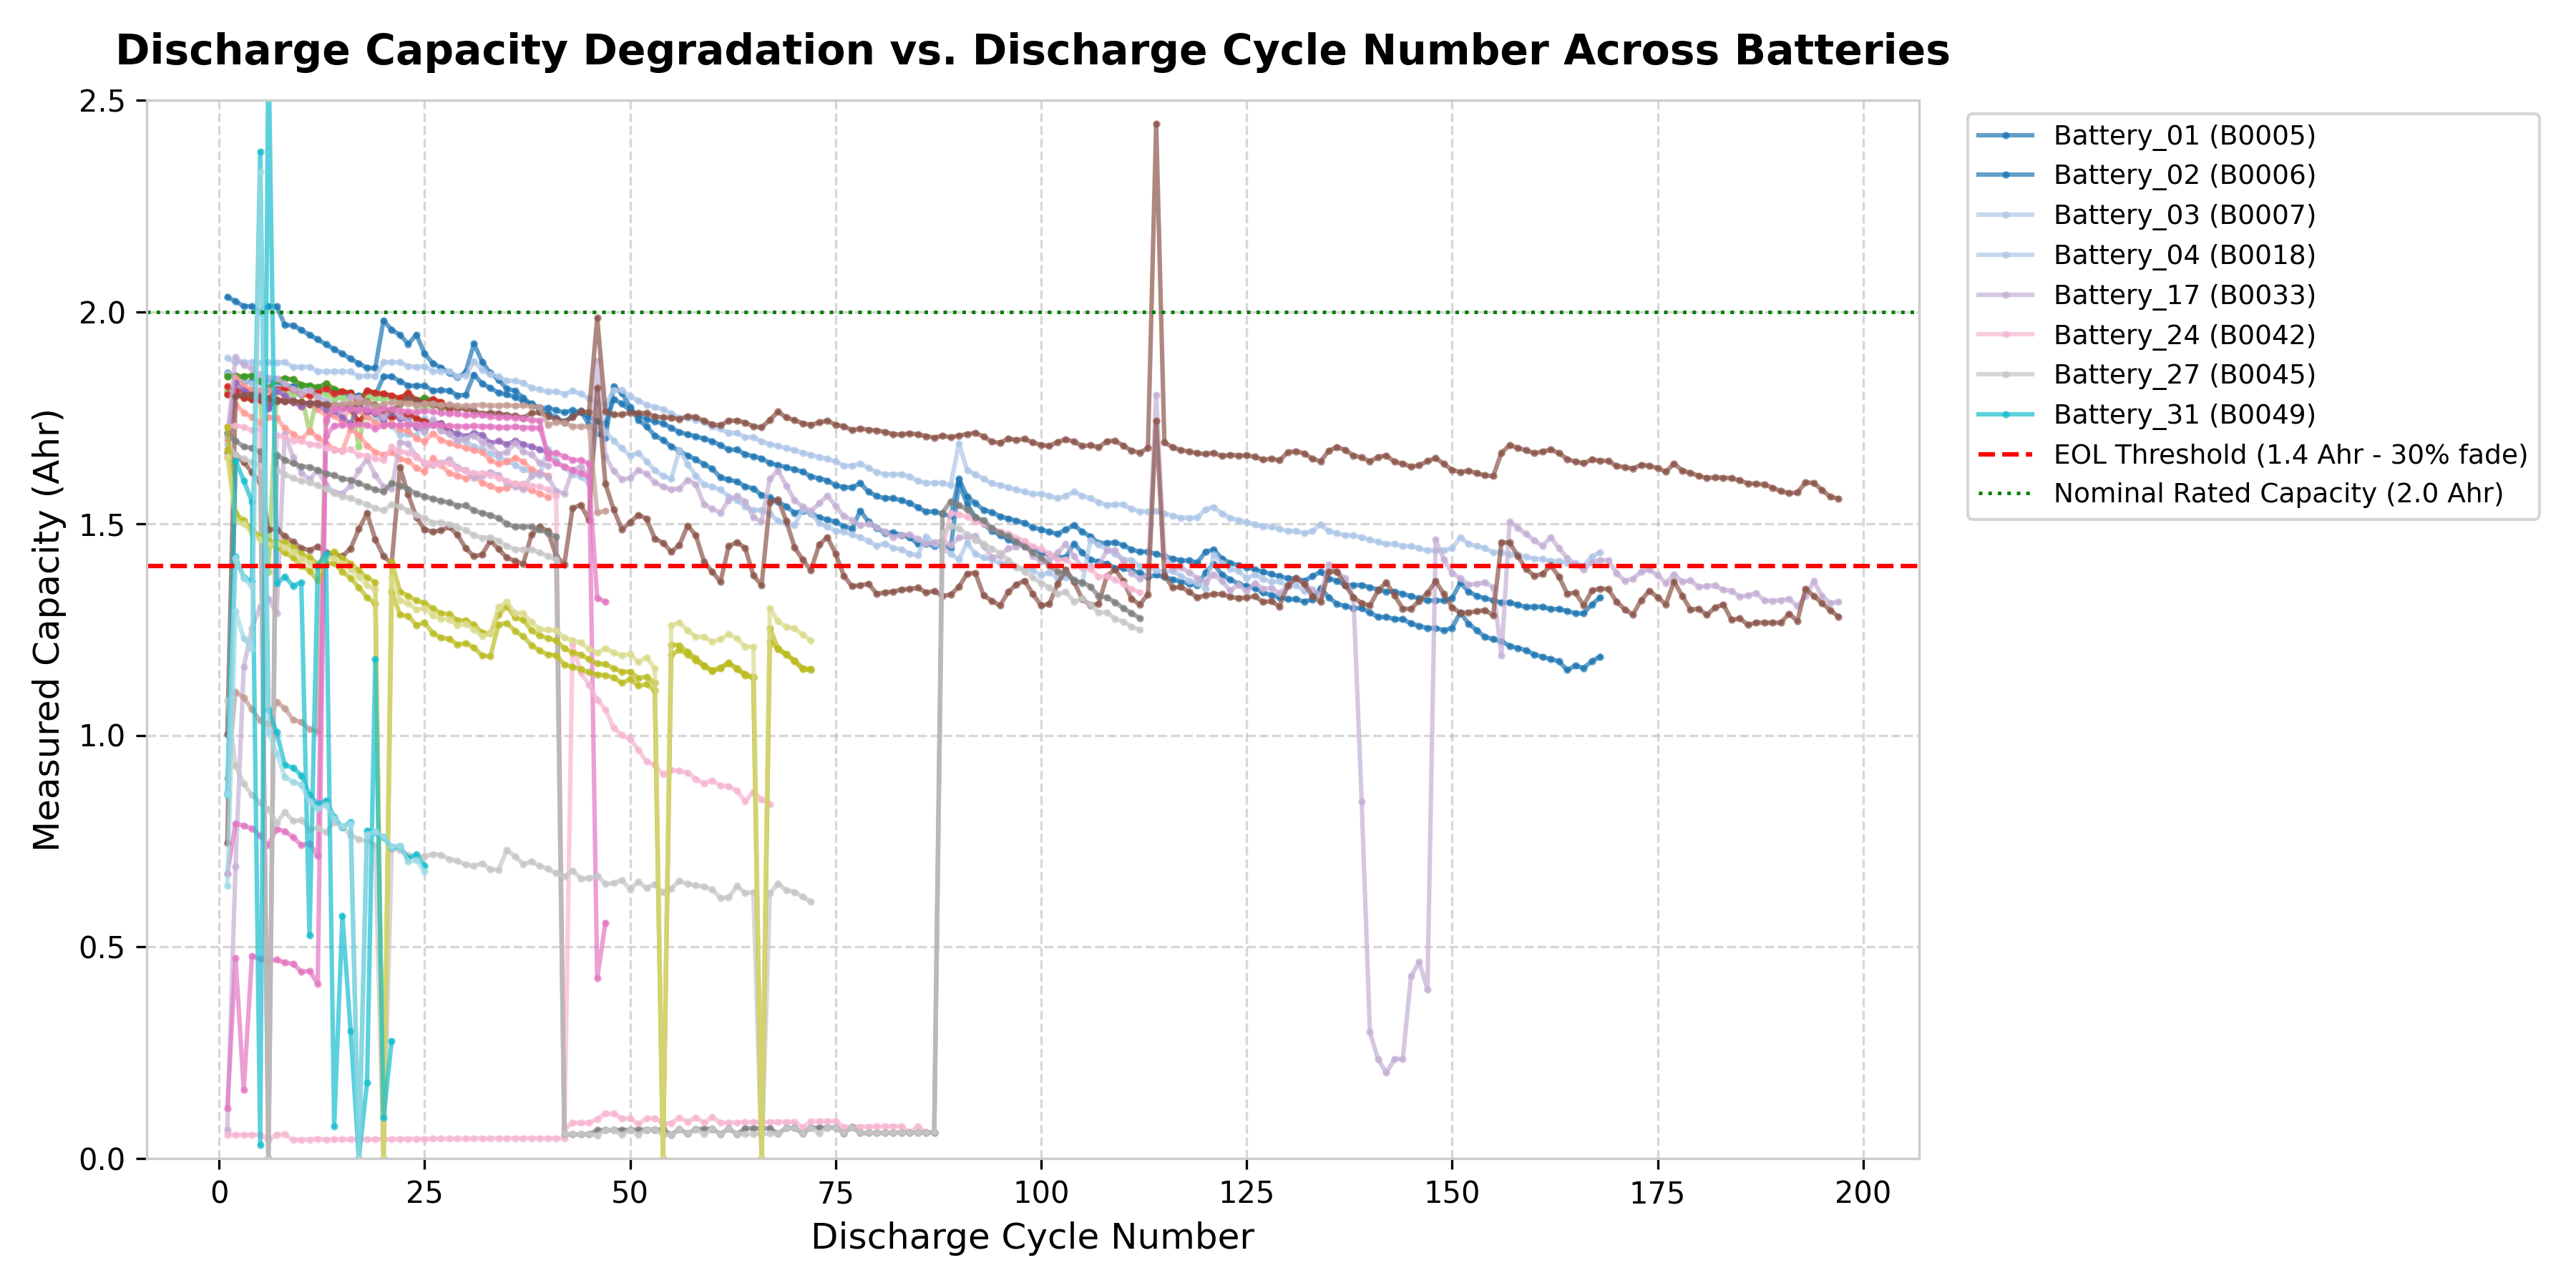

In [7]:
# Visualization 1: Capacity vs Cycle Number
fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
colors = plt.cm.tab20(np.linspace(0, 1, len(battery_folders)))

for idx, bpath in enumerate(battery_folders):
    cyc_file = os.path.join(bpath, 'cycles_index.csv')
    bfolder = os.path.basename(bpath)
    with open(os.path.join(bpath, 'metadata.json')) as f:
        meta = json.load(f)
    b_id = meta['battery_id']
    
    if os.path.exists(cyc_file):
        df_c = pd.read_csv(cyc_file)
        df_dis = df_c[df_c['operation_type'] == 'discharge'].dropna(subset=['capacity']).copy()
        if len(df_dis) > 0:
            df_dis['cycle_seq'] = np.arange(1, len(df_dis) + 1)
            ax.plot(df_dis['cycle_seq'], df_dis['capacity'], marker='.', markersize=3, alpha=0.7, color=colors[idx],
                    label=f"{bfolder} ({b_id})" if idx in [0, 1, 2, 3, 16, 23, 26, 30] else "")

ax.axhline(1.4, color='red', linestyle='--', linewidth=1.5, label='EOL Threshold (1.4 Ahr - 30% fade)')
ax.axhline(2.0, color='green', linestyle=':', linewidth=1.2, label='Nominal Rated Capacity (2.0 Ahr)')
ax.set_title('Discharge Capacity Degradation vs. Discharge Cycle Number Across Batteries', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Discharge Cycle Number', fontsize=12)
ax.set_ylabel('Measured Capacity (Ahr)', fontsize=12)
ax.set_ylim(0, 2.5)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9, frameon=True)
plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'capacity_vs_cycle.png'), bbox_inches='tight')
plt.show()

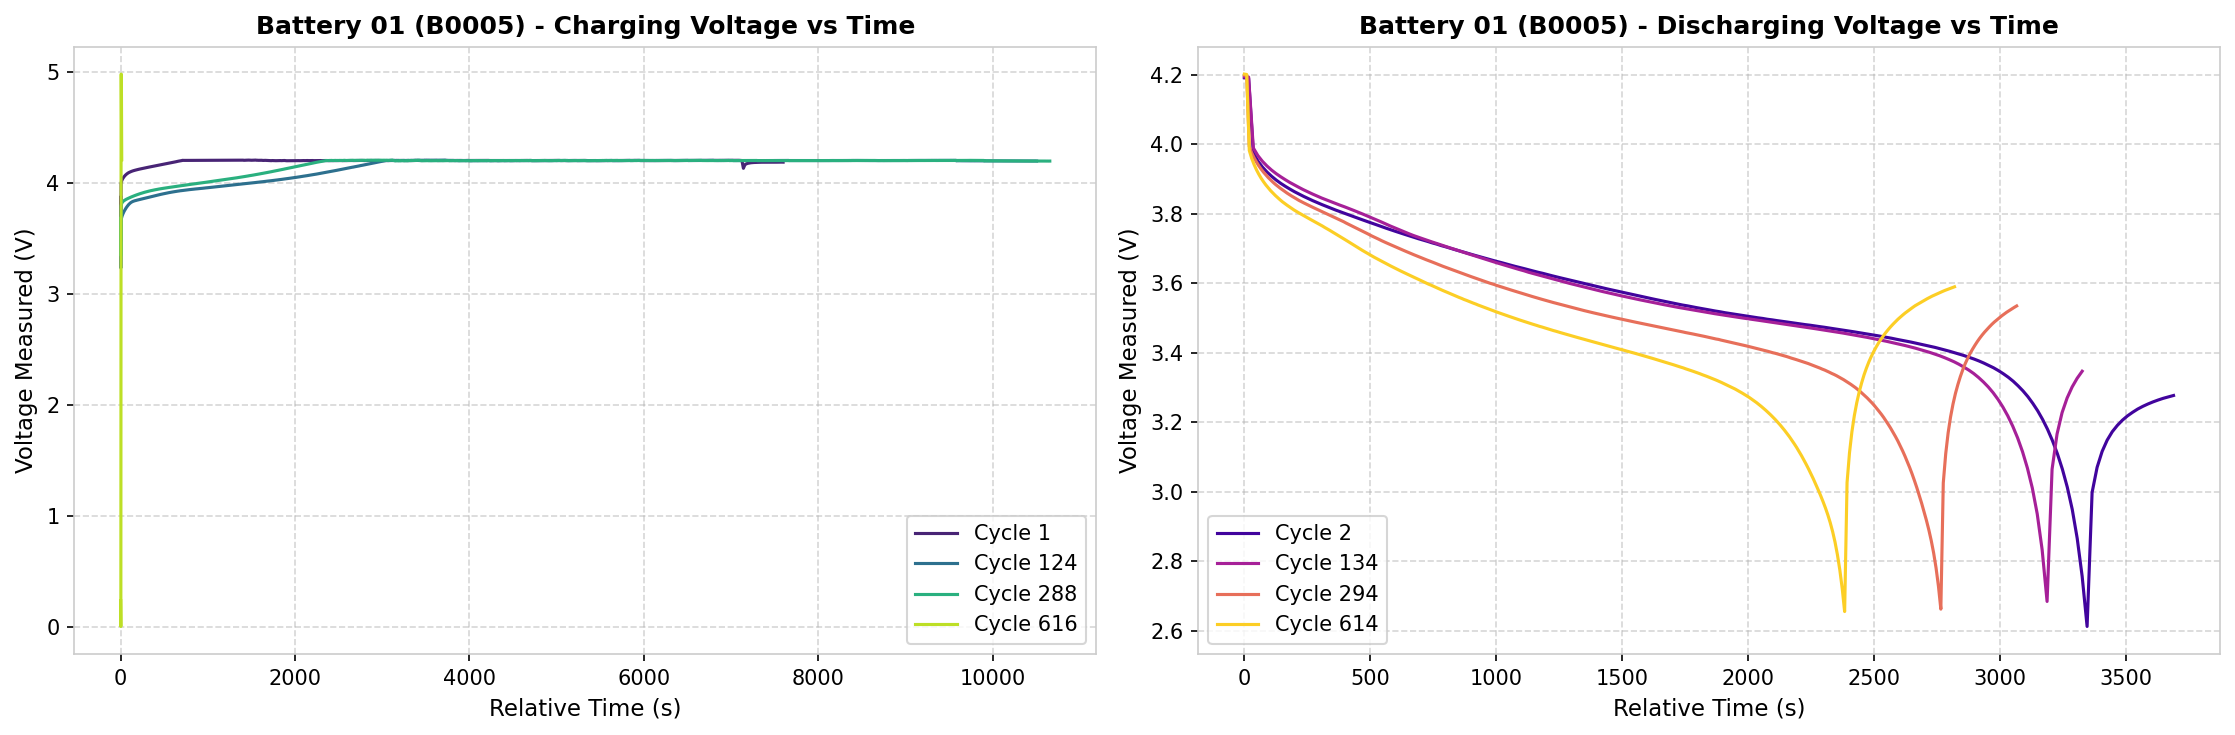

In [8]:
# Visualization 2: Voltage vs Time across Aging (Battery 01 - B0005)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)
b01_chg = pd.read_csv(os.path.join(DATA_DIR, 'Battery_01', 'charge.csv'))
b01_dis = pd.read_csv(os.path.join(DATA_DIR, 'Battery_01', 'discharge.csv'))

chg_cycles = sorted(b01_chg['cycle_index'].unique())
selected_chg = [chg_cycles[0], chg_cycles[len(chg_cycles)//4], chg_cycles[len(chg_cycles)//2], chg_cycles[-1]]
cmap_chg = plt.cm.viridis(np.linspace(0.1, 0.9, len(selected_chg)))

for i, c_idx in enumerate(selected_chg):
    sub = b01_chg[b01_chg['cycle_index'] == c_idx]
    ax1.plot(sub['relative_time_s'], sub['voltage_measured'], label=f'Cycle {c_idx}', color=cmap_chg[i], linewidth=1.5)
ax1.set_title('Battery 01 (B0005) - Charging Voltage vs Time', fontsize=12, fontweight='bold')
ax1.set_xlabel('Relative Time (s)', fontsize=11)
ax1.set_ylabel('Voltage Measured (V)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right', frameon=True)

dis_cycles = sorted(b01_dis['cycle_index'].unique())
selected_dis = [dis_cycles[0], dis_cycles[len(dis_cycles)//4], dis_cycles[len(dis_cycles)//2], dis_cycles[-1]]
cmap_dis = plt.cm.plasma(np.linspace(0.1, 0.9, len(selected_dis)))

for i, c_idx in enumerate(selected_dis):
    sub = b01_dis[b01_dis['cycle_index'] == c_idx]
    ax2.plot(sub['relative_time_s'], sub['voltage_measured'], label=f'Cycle {c_idx}', color=cmap_dis[i], linewidth=1.5)
ax2.set_title('Battery 01 (B0005) - Discharging Voltage vs Time', fontsize=12, fontweight='bold')
ax2.set_xlabel('Relative Time (s)', fontsize=11)
ax2.set_ylabel('Voltage Measured (V)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower left', frameon=True)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'voltage_vs_time.png'), bbox_inches='tight')
plt.show()

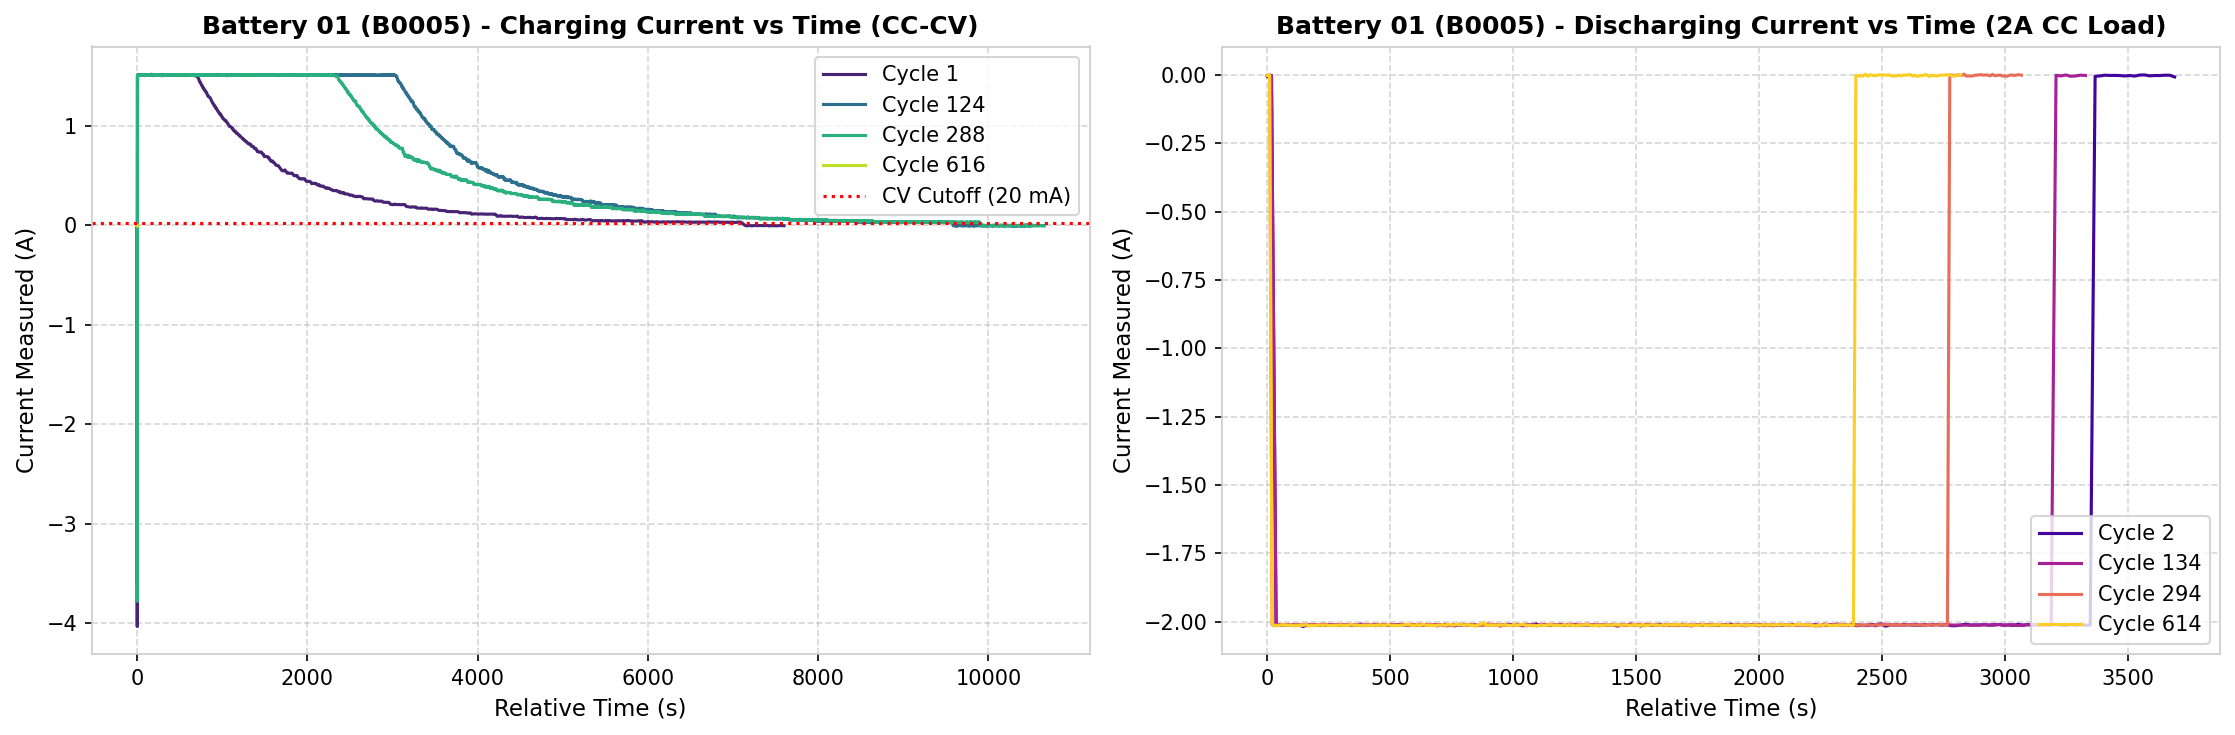

In [9]:
# Visualization 3: Current vs Time
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

for i, c_idx in enumerate(selected_chg):
    sub = b01_chg[b01_chg['cycle_index'] == c_idx]
    ax1.plot(sub['relative_time_s'], sub['current_measured'], label=f'Cycle {c_idx}', color=cmap_chg[i], linewidth=1.5)
ax1.axhline(0.02, color='red', linestyle=':', label='CV Cutoff (20 mA)')
ax1.set_title('Battery 01 (B0005) - Charging Current vs Time (CC-CV)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Relative Time (s)', fontsize=11)
ax1.set_ylabel('Current Measured (A)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', frameon=True)

for i, c_idx in enumerate(selected_dis):
    sub = b01_dis[b01_dis['cycle_index'] == c_idx]
    ax2.plot(sub['relative_time_s'], sub['current_measured'], label=f'Cycle {c_idx}', color=cmap_dis[i], linewidth=1.5)
ax2.set_title('Battery 01 (B0005) - Discharging Current vs Time (2A CC Load)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Relative Time (s)', fontsize=11)
ax2.set_ylabel('Current Measured (A)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'current_vs_time.png'), bbox_inches='tight')
plt.show()

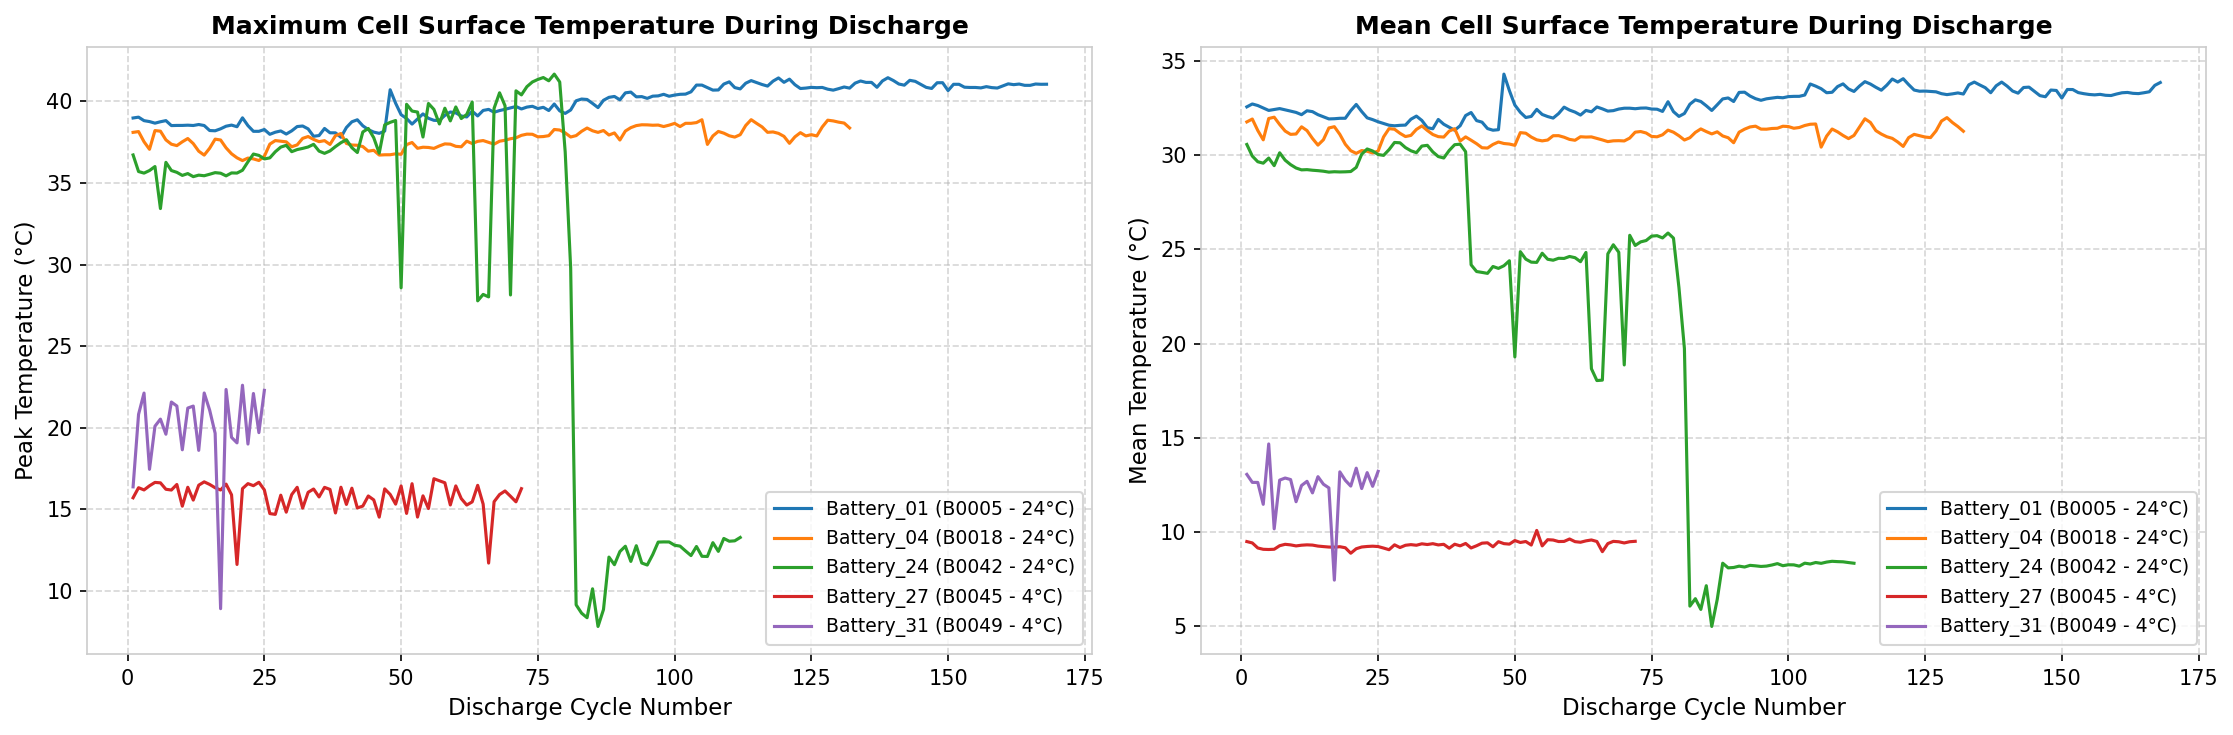

In [10]:
# Visualization 4: Temperature vs Cycle Number (24°C vs 4°C cohorts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

sample_cohorts = [
    (os.path.join(DATA_DIR, 'Battery_01'), 'Battery_01 (B0005 - 24°C)', '#1f77b4'),
    (os.path.join(DATA_DIR, 'Battery_04'), 'Battery_04 (B0018 - 24°C)', '#ff7f0e'),
    (os.path.join(DATA_DIR, 'Battery_24'), 'Battery_24 (B0042 - 24°C)', '#2ca02c'),
    (os.path.join(DATA_DIR, 'Battery_27'), 'Battery_27 (B0045 - 4°C)', '#d62728'),
    (os.path.join(DATA_DIR, 'Battery_31'), 'Battery_31 (B0049 - 4°C)', '#9467bd')
]

for bdir, lbl, col in sample_cohorts:
    d_path = os.path.join(bdir, 'discharge.csv')
    if os.path.exists(d_path):
        df_sub = pd.read_csv(d_path)
        t_stats = df_sub.groupby('cycle_index')['temperature_measured'].agg(['max', 'mean']).reset_index()
        t_stats['cycle_seq'] = np.arange(1, len(t_stats) + 1)
        ax1.plot(t_stats['cycle_seq'], t_stats['max'], label=lbl, color=col, linewidth=1.5)
        ax2.plot(t_stats['cycle_seq'], t_stats['mean'], label=lbl, color=col, linewidth=1.5)

ax1.set_title('Maximum Cell Surface Temperature During Discharge', fontsize=12, fontweight='bold')
ax1.set_xlabel('Discharge Cycle Number', fontsize=11)
ax1.set_ylabel('Peak Temperature (°C)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(frameon=True, fontsize=9)

ax2.set_title('Mean Cell Surface Temperature During Discharge', fontsize=12, fontweight='bold')
ax2.set_xlabel('Discharge Cycle Number', fontsize=11)
ax2.set_ylabel('Mean Temperature (°C)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(frameon=True, fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'temperature_vs_cycle.png'), bbox_inches='tight')
plt.show()

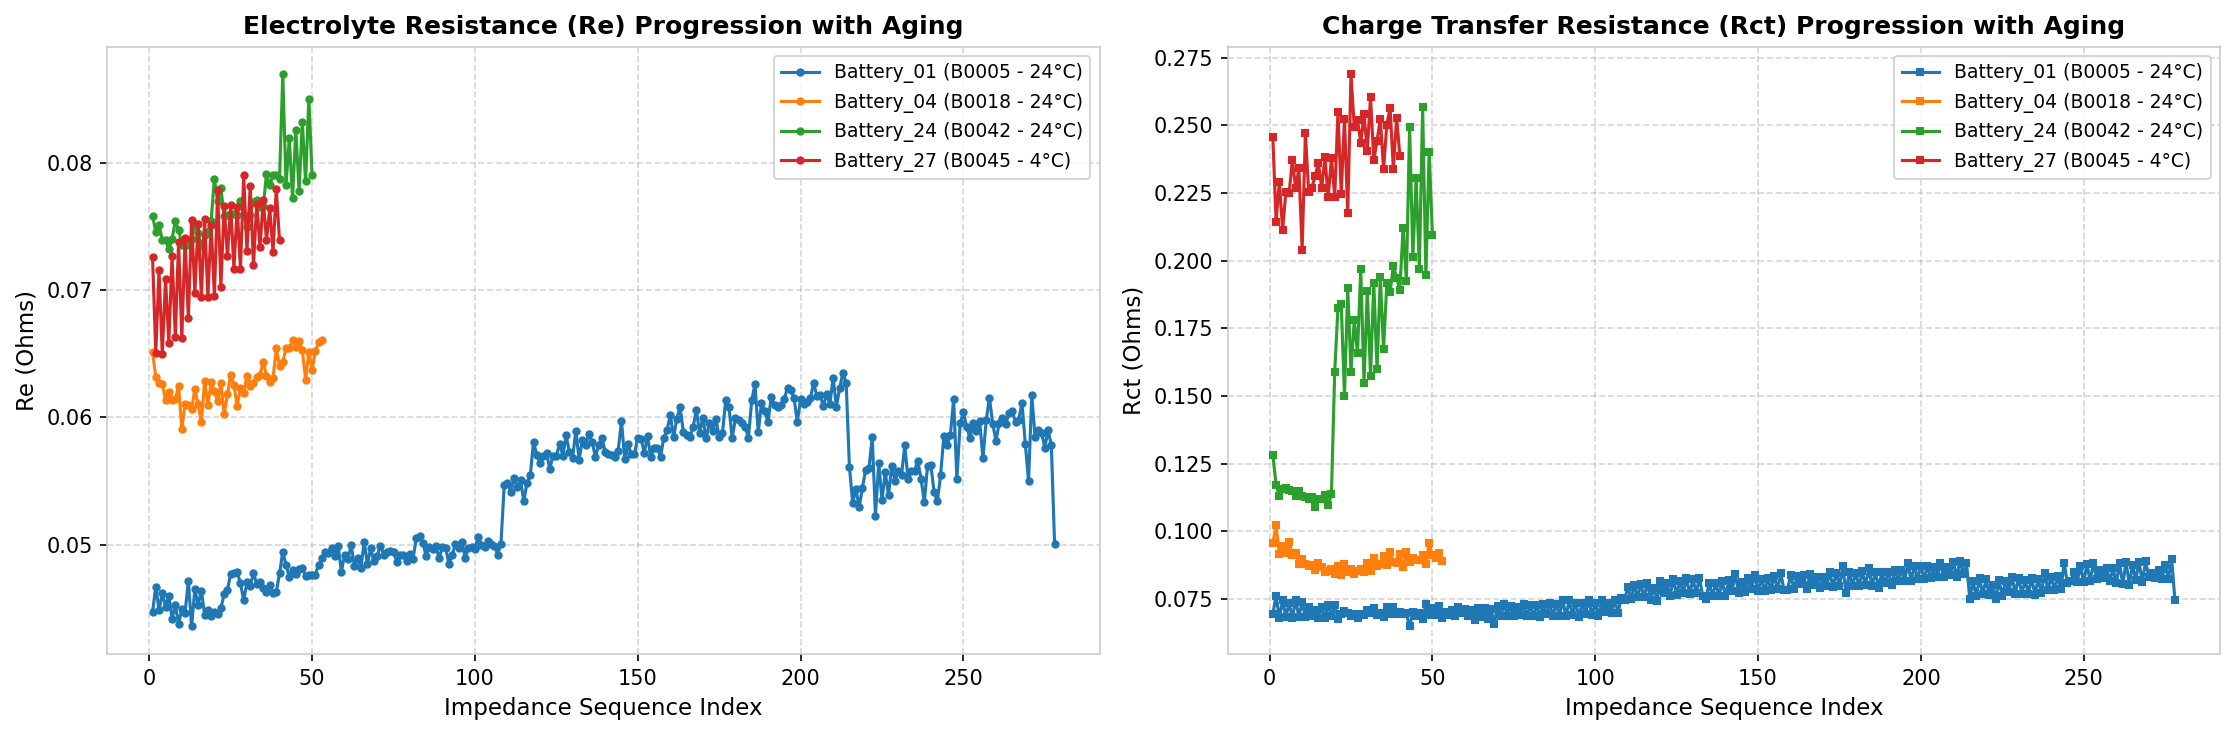

In [11]:
# Visualization 5: Resistance (Re & Rct) vs Cycle Number
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

for bdir, lbl, col in sample_cohorts[:4]:
    imp_path = os.path.join(bdir, 'impedance.csv')
    if os.path.exists(imp_path):
        df_i = pd.read_csv(imp_path)
        df_i_valid = df_i[(df_i['Re'] > 0) & (df_i['Re'] < 1.0) & (df_i['Rct'] > 0) & (df_i['Rct'] < 2.0)].copy()
        df_i_valid['imp_seq'] = np.arange(1, len(df_i_valid) + 1)
        if len(df_i_valid) > 0:
            ax1.plot(df_i_valid['imp_seq'], df_i_valid['Re'], marker='o', markersize=3, label=lbl, color=col)
            ax2.plot(df_i_valid['imp_seq'], df_i_valid['Rct'], marker='s', markersize=3, label=lbl, color=col)

ax1.set_title('Electrolyte Resistance (Re) Progression with Aging', fontsize=12, fontweight='bold')
ax1.set_xlabel('Impedance Sequence Index', fontsize=11)
ax1.set_ylabel('Re (Ohms)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(frameon=True, fontsize=9)

ax2.set_title('Charge Transfer Resistance (Rct) Progression with Aging', fontsize=12, fontweight='bold')
ax2.set_xlabel('Impedance Sequence Index', fontsize=11)
ax2.set_ylabel('Rct (Ohms)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(frameon=True, fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'resistance_vs_cycle.png'), bbox_inches='tight')
plt.show()

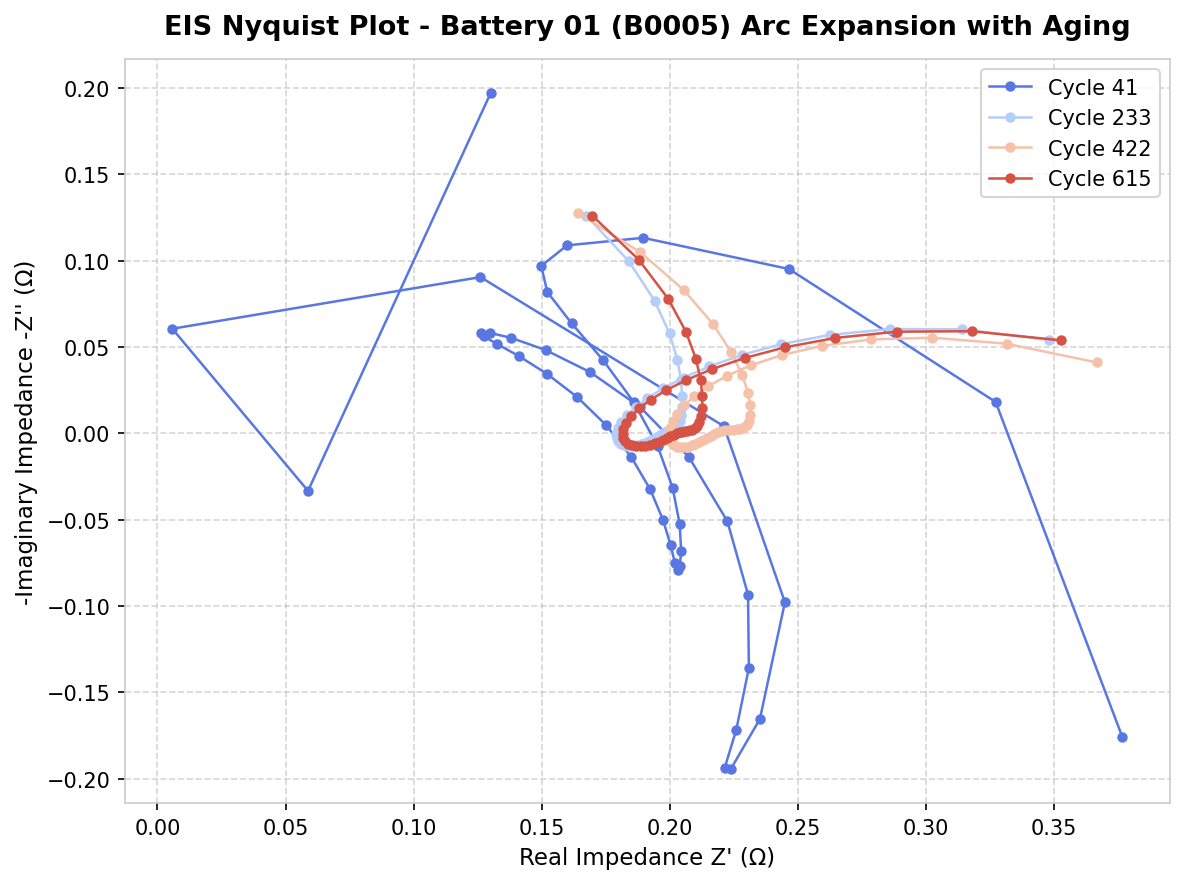

In [12]:
# Visualization 6: EIS Nyquist Plots across Degradation (Battery 01 - B0005)
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
spec_path = os.path.join(DATA_DIR, 'Battery_01', 'impedance_spectrum.csv')

if os.path.exists(spec_path):
    df_spec = pd.read_csv(spec_path)
    spec_cyc = sorted(df_spec['cycle_index'].unique())
    sel_spec = [spec_cyc[0], spec_cyc[len(spec_cyc)//3], spec_cyc[2*len(spec_cyc)//3], spec_cyc[-1]]
    cmap_nyq = plt.cm.coolwarm(np.linspace(0.1, 0.9, len(sel_spec)))
    
    for i, c_idx in enumerate(sel_spec):
        sub = df_spec[df_spec['cycle_index'] == c_idx].copy()
        sub = sub[(sub['battery_impedance_real'] > 0) & (sub['battery_impedance_real'] < 1.0)]
        if len(sub) > 0:
            ax.plot(sub['battery_impedance_real'], -sub['battery_impedance_imag'],
                    marker='o', markersize=4, label=f'Cycle {c_idx}', color=cmap_nyq[i], linewidth=1.2)

ax.set_title('EIS Nyquist Plot - Battery 01 (B0005) Arc Expansion with Aging', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Real Impedance Z' (Ω)", fontsize=11)
ax.set_ylabel("-Imaginary Impedance -Z'' (Ω)", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'impedance_nyquist.png'), bbox_inches='tight')
plt.show()

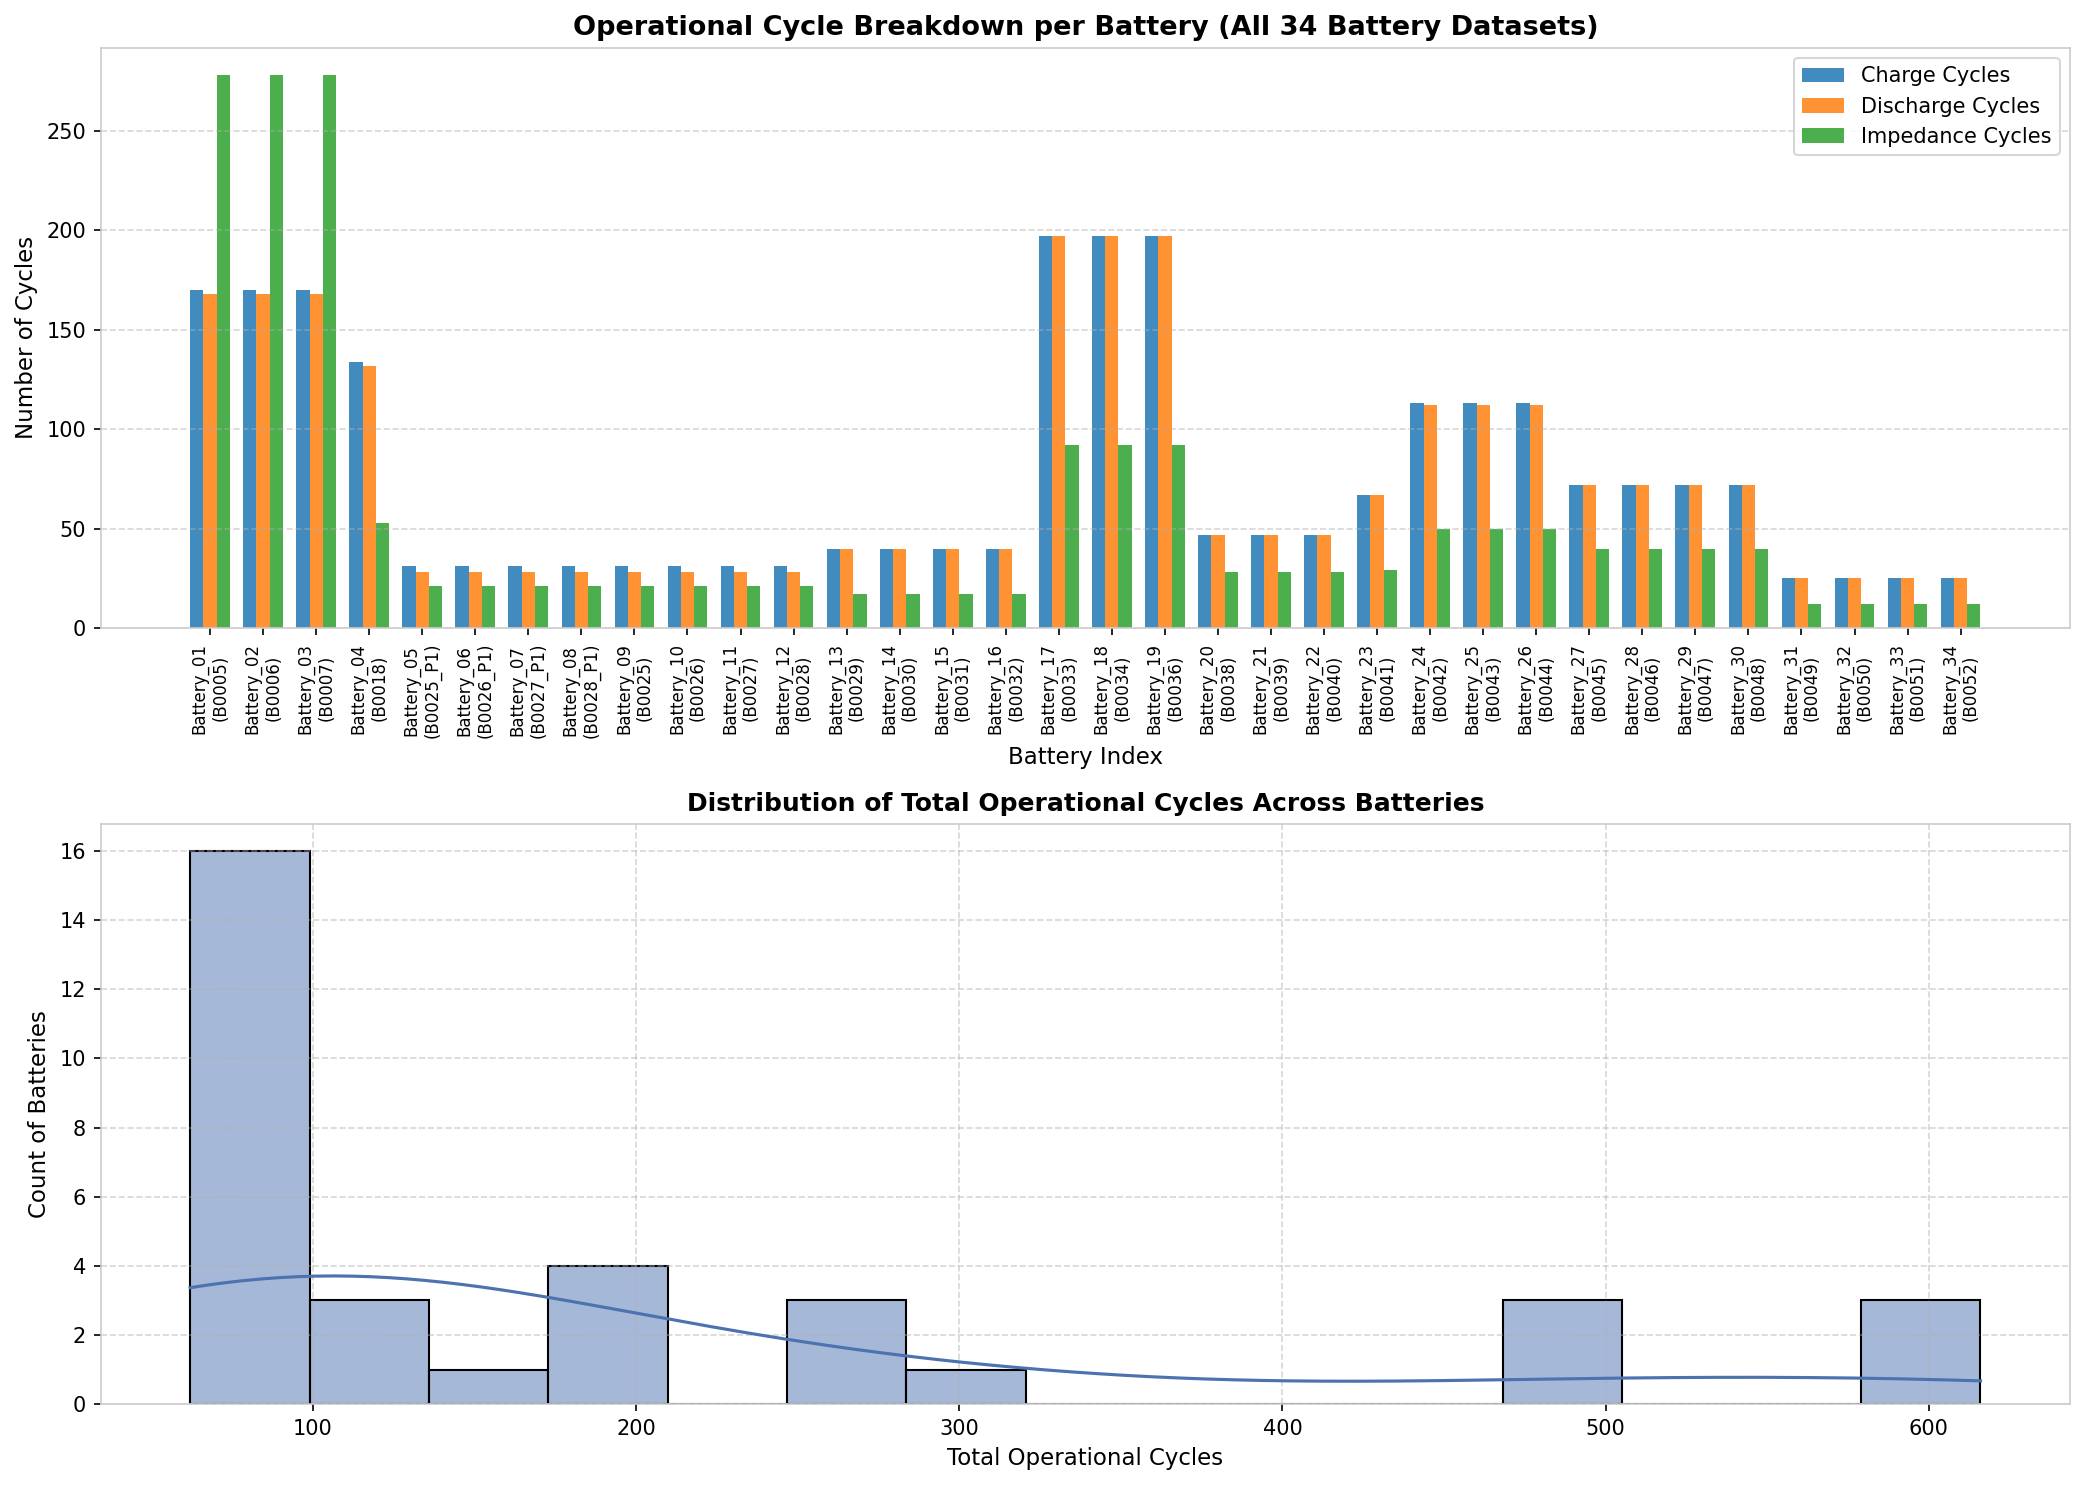

In [13]:
# Visualization 7: Operational Cycle Count Breakdown Across All 38 batteries (34 initial + 4 added)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), dpi=150)

idx_arr = np.arange(len(df_battery_summary))
bar_w = 0.25
ax1.bar(idx_arr - bar_w, df_battery_summary['charge_cycles'], width=bar_w, label='Charge Cycles', color='#1f77b4', alpha=0.85)
ax1.bar(idx_arr, df_battery_summary['discharge_cycles'], width=bar_w, label='Discharge Cycles', color='#ff7f0e', alpha=0.85)
ax1.bar(idx_arr + bar_w, df_battery_summary['impedance_cycles'], width=bar_w, label='Impedance Cycles', color='#2ca02c', alpha=0.85)

ax1.set_title('Operational Cycle Breakdown per Battery (All 34 Battery Datasets)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Battery Index', fontsize=11)
ax1.set_ylabel('Number of Cycles', fontsize=11)
ax1.set_xticks(idx_arr)
ax1.set_xticklabels([f"{r.battery_folder}\n({r.battery_id})" for _, r in df_battery_summary.iterrows()], rotation=90, fontsize=8)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
ax1.legend(frameon=True, loc='upper right')

sns.histplot(df_battery_summary['total_cycles'], bins=15, kde=True, ax=ax2, color='#4c72b0')
ax2.set_title('Distribution of Total Operational Cycles Across Batteries', fontsize=12, fontweight='bold')
ax2.set_xlabel('Total Operational Cycles', fontsize=11)
ax2.set_ylabel('Count of Batteries', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'cycle_count_distribution.png'), bbox_inches='tight')
plt.show()

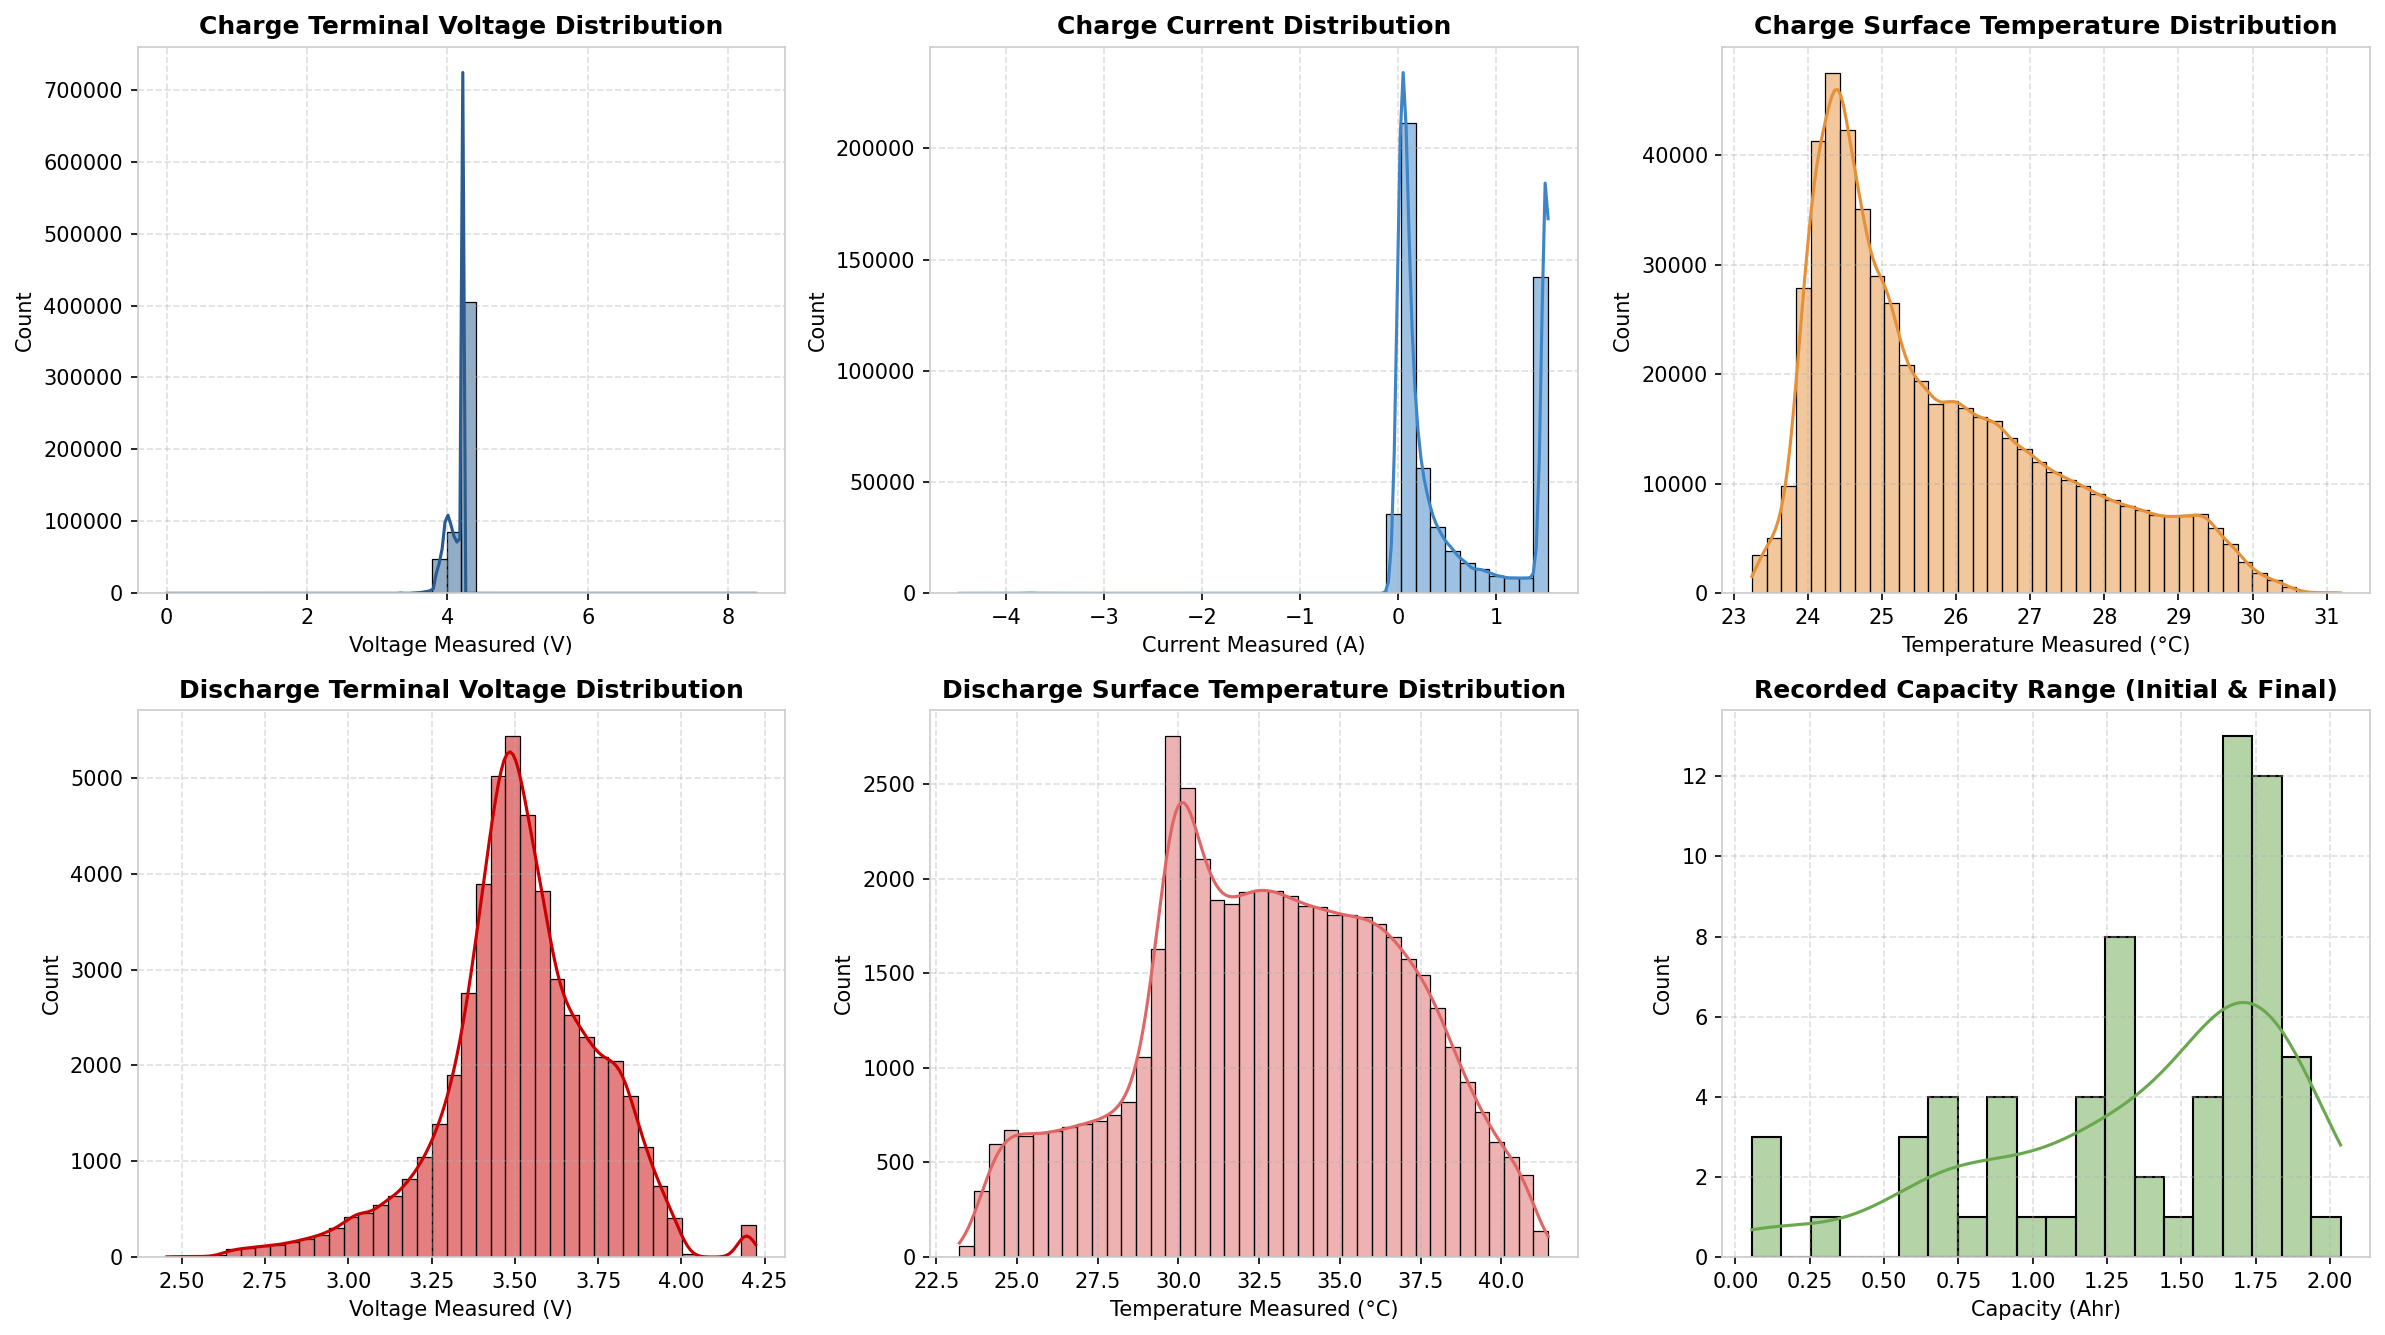

In [1]:
# Visualization 8: Feature Distributions (Multi-panel histograms & KDEs)
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=150)

sns.histplot(b01_chg['voltage_measured'], bins=40, kde=True, ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set_title('Charge Terminal Voltage Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Voltage Measured (V)')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)

sns.histplot(b01_chg['current_measured'], bins=40, kde=True, ax=axes[0, 1], color='#3d85c6')
axes[0, 1].set_title('Charge Current Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Current Measured (A)')
axes[0, 1].grid(True, linestyle='--', alpha=0.4)

sns.histplot(b01_chg['temperature_measured'], bins=40, kde=True, ax=axes[0, 2], color='#e69138')
axes[0, 2].set_title('Charge Surface Temperature Distribution', fontweight='bold')
axes[0, 2].set_xlabel('Temperature Measured (°C)')
axes[0, 2].grid(True, linestyle='--', alpha=0.4)

sns.histplot(b01_dis['voltage_measured'], bins=40, kde=True, ax=axes[1, 0], color='#cc0000')
axes[1, 0].set_title('Discharge Terminal Voltage Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Voltage Measured (V)')
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

sns.histplot(b01_dis['temperature_measured'], bins=40, kde=True, ax=axes[1, 1], color='#e06666')
axes[1, 1].set_title('Discharge Surface Temperature Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Temperature Measured (°C)')
axes[1, 1].grid(True, linestyle='--', alpha=0.4)

caps_all = df_battery_summary['initial_capacity_Ahr'].dropna().tolist() + df_battery_summary['final_capacity_Ahr'].dropna().tolist()
sns.histplot(caps_all, bins=20, kde=True, ax=axes[1, 2], color='#6aa84f')
axes[1, 2].set_title('Recorded Capacity Range (Initial & Final)', fontweight='bold')
axes[1, 2].set_xlabel('Capacity (Ahr)')
axes[1, 2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'feature_distributions.png'), bbox_inches='tight')
plt.show()

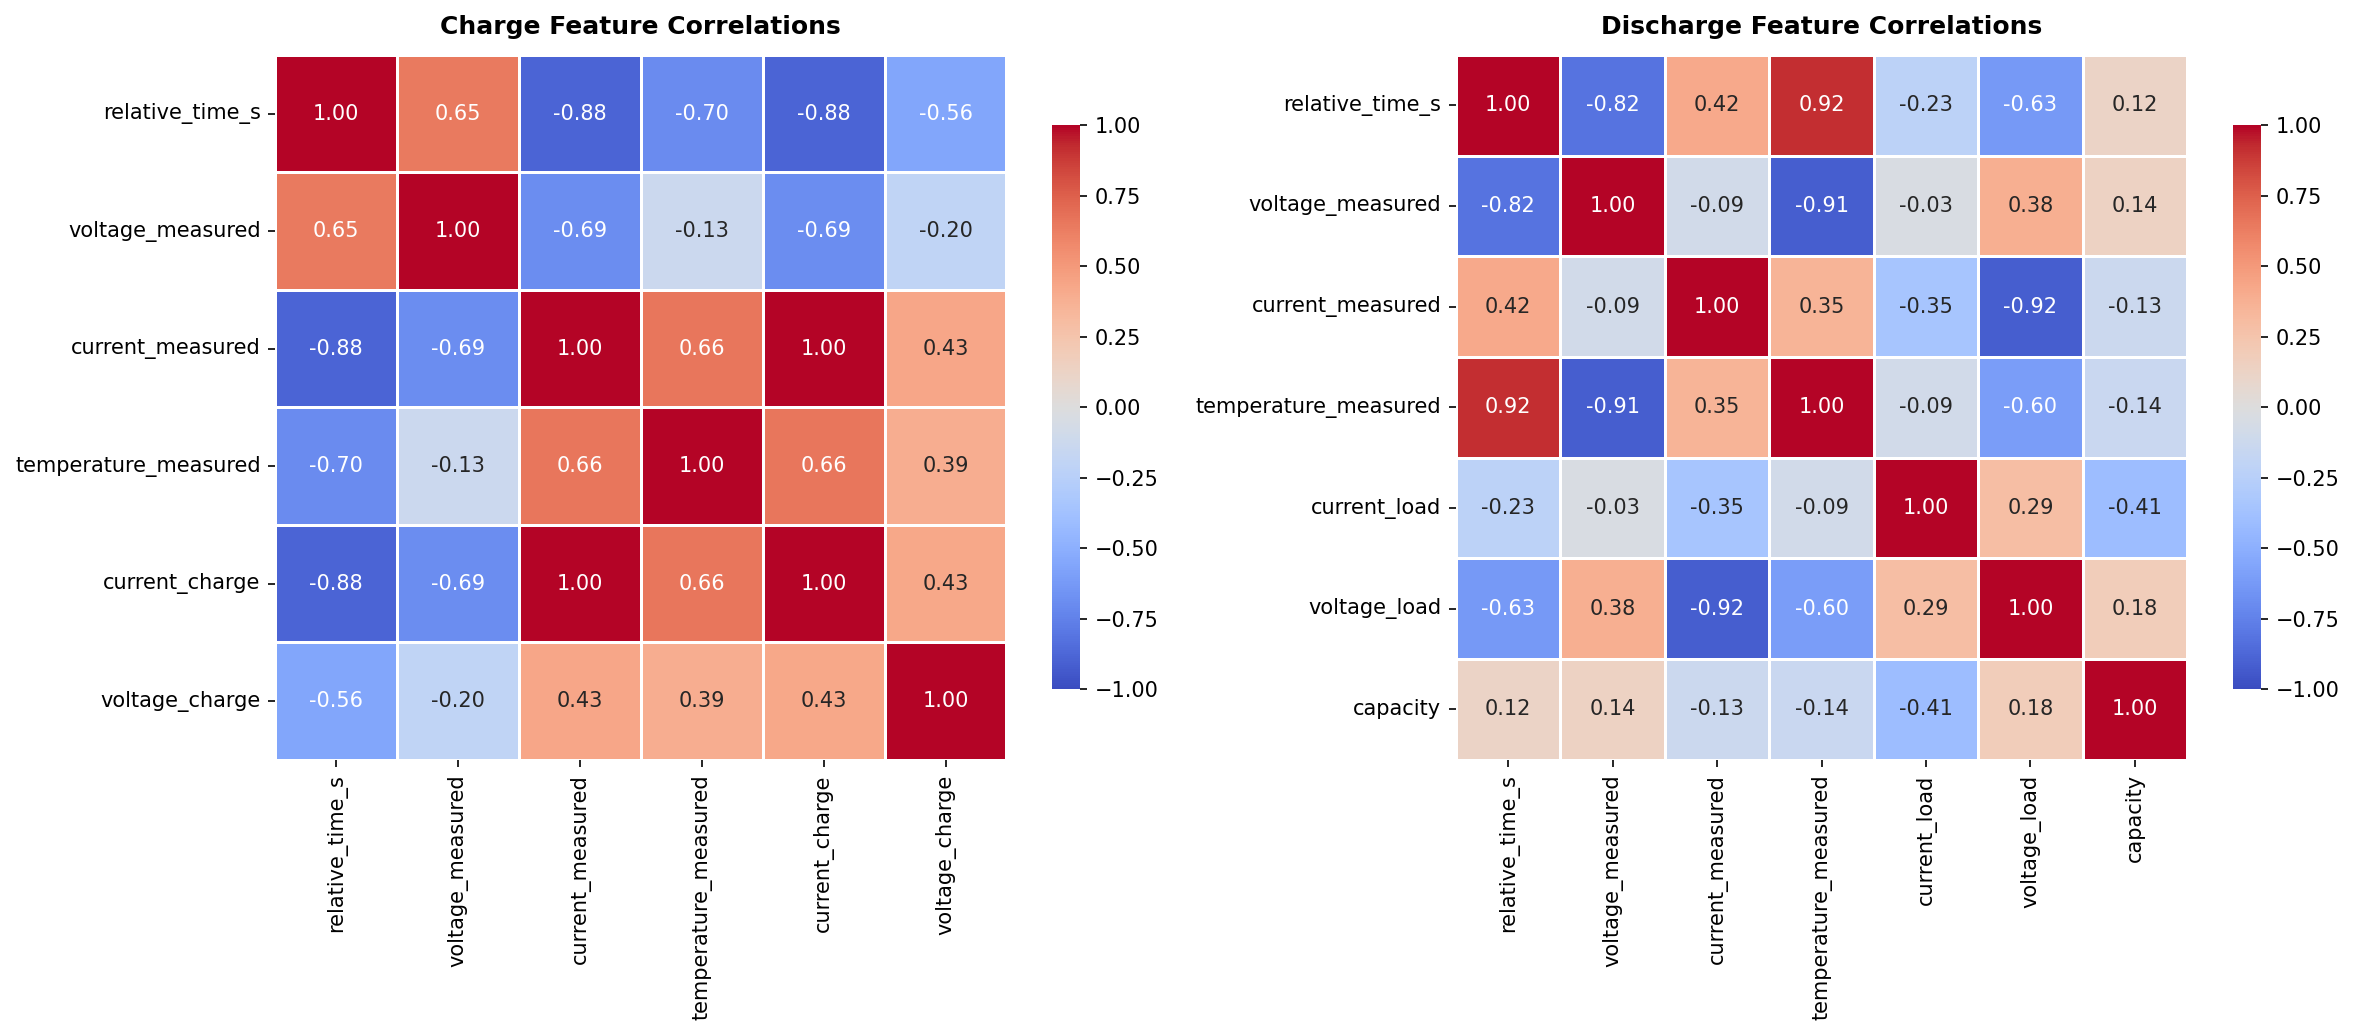

In [15]:
# Visualization 9: Correlation Heatmaps for Charge and Discharge Operations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=150)

chg_cols = ['relative_time_s', 'voltage_measured', 'current_measured', 'temperature_measured', 'current_charge', 'voltage_charge']
corr_chg = b01_chg[chg_cols].corr()
sns.heatmap(corr_chg, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5, ax=ax1, cbar_kws={'shrink': 0.8})
ax1.set_title('Charge Feature Correlations', fontsize=12, fontweight='bold', pad=10)

dis_cols = ['relative_time_s', 'voltage_measured', 'current_measured', 'temperature_measured', 'current_load', 'voltage_load', 'capacity']
corr_dis = b01_dis[dis_cols].corr()
sns.heatmap(corr_dis, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5, ax=ax2, cbar_kws={'shrink': 0.8})
ax2.set_title('Discharge Feature Correlations', fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
fig.savefig(os.path.join(VIZ_DIR, 'correlation_heatmap.png'), bbox_inches='tight')
plt.show()

### 7. Key Physical Observations
- Summarizes temperature sensitivity (accelerated fade at 4 °C) and capacity regeneration behavior.
